# Duka Electronics: H1 2026 Sales Review & H2 Focus
**Engagement 2 · One-Page Board Report & Chart Makeover**

## Storyboard
* **Audience:** Duka Electronics Board of Directors (non-technical executives reviewing performance on mobile devices prior to next week's board meeting).
* **Decision:** Decide where to concentrate commercial, inventory, and digital-channel focus for the second half (H2) of 2026.
* **Big Idea:** Duka Electronics generated **KES 71.79M** across **1,000** orders in H1 2026, led by **Nairobi** and high-ticket **Laptops**—creating a clear H2 opportunity to scale high-margin device sales and digital/branch execution across growth markets.
* **Situation:** Across Jan–Jun 2026 (`duka_sales.csv`, 1,000 orders), total revenue reached **KES 71,792,500**, with **Nairobi** leading branches (**KES 26,106,100**; 376 orders) and **Laptops** driving top revenue (**KES 41,535,000**; 639 units) while **Tablets** led unit volume (**691** units).
* **Complication:** Revenue is heavily concentrated in Nairobi and premium electronics, monthly revenue fluctuated between **April (`KES 13,518,300`)** and **June (`KES 10,903,400`)**, and regional branches (`Mombasa`, `Nakuru`, `Kisumu`, `Eldoret`) have room for stronger high-value and multi-channel growth.
* **Resolution:** Prioritise H2 execution around (1) sustaining core Laptop and Tablet availability while pairing high-ticket devices with value accessories, (2) expanding digital and branch conversion outside Nairobi, and (3) smoothing mid-year seasonal dips with targeted H2 campaigns.

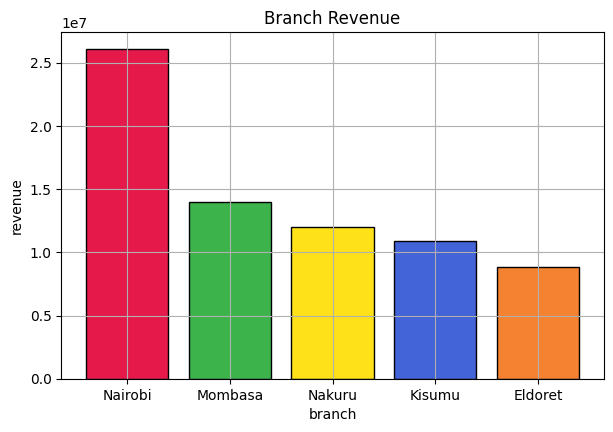

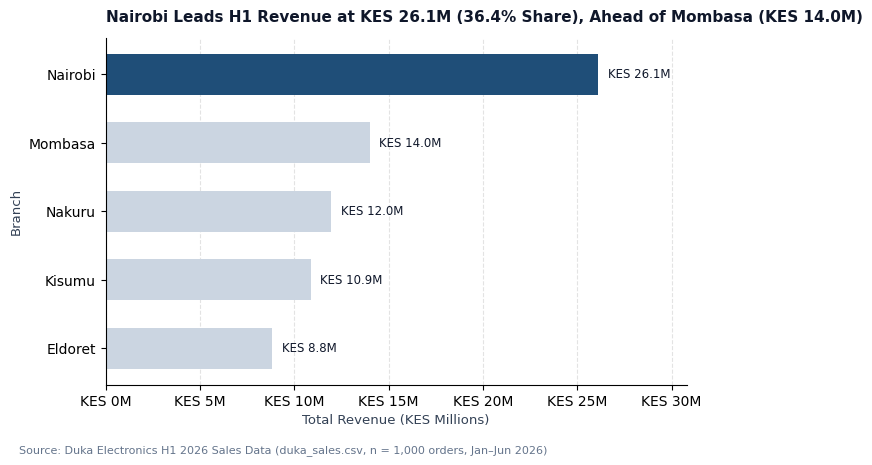

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.gridspec import GridSpec

os.makedirs("figures", exist_ok=True)
os.makedirs("reports", exist_ok=True)

# Generate Duka Electronics dataset (seed 2026) if not already in working directory
if os.path.exists("duka_sales.csv"):
    df = pd.read_csv("duka_sales.csv", parse_dates=["order_date"])
else:
    rng = np.random.default_rng(2026)
    n = 1000
    products = {
        "Phone": 15000,
        "Laptop": 65000,
        "Headphones": 2500,
        "Tablet": 28000,
        "Charger": 1200,
    }
    df = pd.DataFrame({
        "order_id": range(1001, 1001 + n),
        "order_date": pd.to_datetime("2026-01-01") + pd.to_timedelta(rng.integers(0, 180, n), unit="D"),
        "branch": rng.choice(["Nairobi", "Mombasa", "Kisumu", "Nakuru", "Eldoret"], n, p=[0.4, 0.2, 0.15, 0.15, 0.1]),
        "product": rng.choice(list(products), n),
        "quantity": rng.integers(1, 6, n),
        "channel": rng.choice(["In-store", "Online", "Phone order"], n, p=[0.55, 0.35, 0.10]),
    })
    df["unit_price"] = df["product"].map(products)

df["revenue"] = df["quantity"] * df["unit_price"]
df["month"] = df["order_date"].dt.to_period("M").astype(str)
df["price_band"] = np.where(df["unit_price"] >= 28000, "Premium (>=KES 28k)", "Value (<KES 28k)")

# ---------------------------------------------------------
# 1. BEFORE CHART (Cluttered, rainbow bars, no insight title)
# ---------------------------------------------------------
branch_rev = df.groupby("branch")["revenue"].sum().sort_values(ascending=False)

fig_b, ax_b = plt.subplots(figsize=(7, 4.5))
ax_b.bar(
    branch_rev.index,
    branch_rev.values,
    color=["#e6194b", "#3cb44b", "#ffe119", "#4363d8", "#f58231"],
    edgecolor="black",
)
ax_b.set_title("Branch Revenue")
ax_b.set_xlabel("branch")
ax_b.set_ylabel("revenue")
ax_b.grid(True)
fig_b.savefig("figures/before.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig_b)

# ---------------------------------------------------------
# 2. AFTER CHART (Decluttered, purposeful accent colour, insight title, units, source)
# ---------------------------------------------------------
top_branch = branch_rev.index[0]
top_rev_m = branch_rev.iloc[0] / 1e6
second_rev_m = branch_rev.iloc[1] / 1e6
share_top = branch_rev.iloc[0] / branch_rev.sum() * 100

after_colors = ["#1F4E78" if b == top_branch else "#CBD5E1" for b in branch_rev.index]

plt.rcParams["font.sans-serif"] = "DejaVu Sans"
fig_a, ax_a = plt.subplots(figsize=(7.5, 4.5))
bars = ax_a.barh(branch_rev.index[::-1], (branch_rev.values / 1e6)[::-1], color=after_colors[::-1], height=0.6)

ax_a.set_title(
    f"{top_branch} Leads H1 Revenue at KES {top_rev_m:.1f}M ({share_top:.1f}% Share), Ahead of Mombasa (KES {second_rev_m:.1f}M)",
    fontsize=11,
    fontweight="bold",
    loc="left",
    pad=12,
    color="#0F172A",
)
ax_a.set_xlabel("Total Revenue (KES Millions)", fontsize=9.5, color="#334155")
ax_a.set_ylabel("Branch", fontsize=9.5, color="#334155")
ax_a.xaxis.set_major_formatter(mtick.StrMethodFormatter("KES {x:.0f}M"))
ax_a.set_xlim(0, (branch_rev.max() / 1e6) * 1.18)

for bar in bars:
    w = bar.get_width()
    ax_a.text(w + 0.5, bar.get_y() + bar.get_height() / 2, f"KES {w:.1f}M", va="center", ha="left", fontsize=8.5, color="#0F172A")

ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)
ax_a.grid(axis="x", linestyle="--", alpha=0.35)
ax_a.set_axisbelow(True)

fig_a.text(0.01, -0.04, "Source: Duka Electronics H1 2026 Sales Data (duka_sales.csv, n = 1,000 orders, Jan–Jun 2026)", fontsize=8, color="#64748B")
fig_a.savefig("figures/after.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig_a)

### Before-and-After Chart Makeover: Design Changes Explained
* **Action-Oriented Insight Title:** Replaced the generic label `"Branch Revenue"` with a specific takeaway stating Nairobi's lead and revenue share in KES millions.
* **Horizontal Orientation & Direct Data Labels:** Swapped to a horizontal bar chart so branch names read cleanly without crowding, with exact KES million values labelled directly on each bar.
* **Purposeful Accent Colour & Decluttering:** Replaced distracting multi-colour bars and heavy gridlines with a single highlight tone (`#1F4E78`) for the #1 branch against muted slate bars (`#CBD5E1`), removing top/right spines and full grid boxes.
* **Explicit Units & Source Line:** Formatted x-axis ticks and labels in `KES Millions` and added a clear source line referencing `duka_sales.csv`.

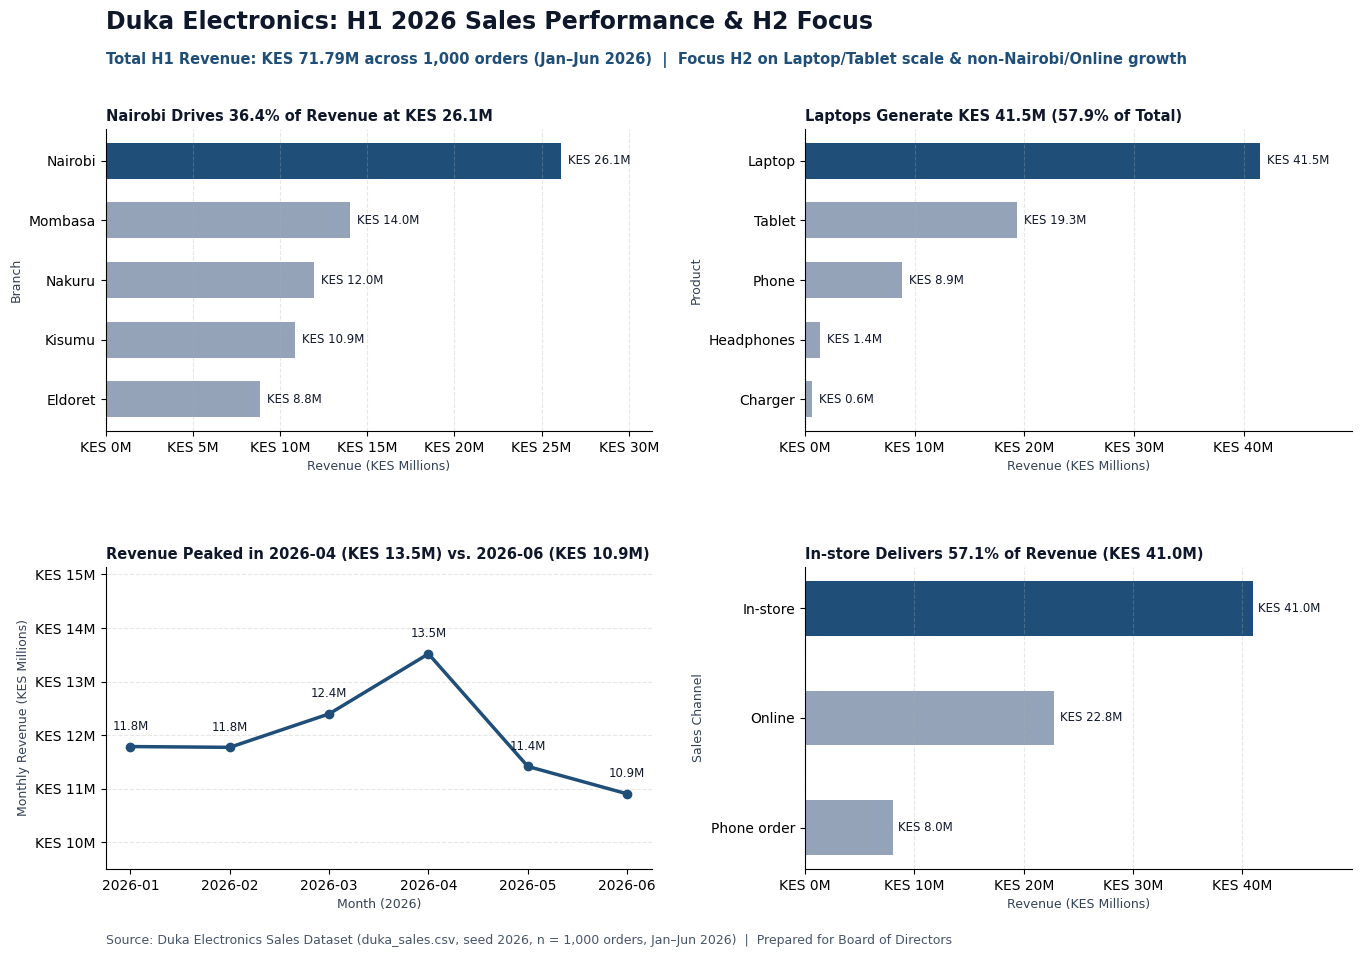

Saved reports/duka_board_report.png successfully.


In [2]:
# Build Single-Page Visual Board Report (4 charts, mobile-legible typography, units & source lines)
prod_rev = (df.groupby("product")["revenue"].sum() / 1e6).sort_values(ascending=True)
monthly_rev = df.groupby("month")["revenue"].sum() / 1e6
channel_rev = (df.groupby("channel")["revenue"].sum() / 1e6).sort_values(ascending=True)

best_m = monthly_rev.idxmax()
best_v = monthly_rev.max()
worst_m = monthly_rev.idxmin()
worst_v = monthly_rev.min()

top_prod = prod_rev.index[-1]
top_prod_v = prod_rev.iloc[-1]

top_chan = channel_rev.index[-1]
top_chan_share = channel_rev.iloc[-1] / channel_rev.sum() * 100

fig = plt.figure(figsize=(14, 10), facecolor="#FFFFFF")
gs = GridSpec(2, 2, figure=fig, hspace=0.45, wspace=0.28, top=0.84, bottom=0.10, left=0.07, right=0.96)

# Header Banner
fig.text(0.07, 0.94, "Duka Electronics: H1 2026 Sales Performance & H2 Focus", fontsize=17, fontweight="bold", color="#0F172A")
fig.text(
    0.07,
    0.905,
    f"Total H1 Revenue: KES {df['revenue'].sum()/1e6:.2f}M across {len(df):,} orders (Jan–Jun 2026)  |  Focus H2 on Laptop/Tablet scale & non-Nairobi/Online growth",
    fontsize=10.5,
    color="#1F4E78",
    fontweight="bold",
)

# Panel 1 (Top-Left): Revenue by Branch
ax1 = fig.add_subplot(gs[0, 0])
b_series = (df.groupby("branch")["revenue"].sum() / 1e6).sort_values(ascending=True)
b_cols = ["#1F4E78" if idx == b_series.index[-1] else "#94A3B8" for idx in b_series.index]
ax1.barh(b_series.index, b_series.values, color=b_cols, height=0.6)
ax1.set_title(f"Nairobi Drives {b_series.iloc[-1]/b_series.sum()*100:.1f}% of Revenue at KES {b_series.iloc[-1]:.1f}M", fontsize=10.5, fontweight="bold", loc="left", color="#0F172A")
ax1.set_xlabel("Revenue (KES Millions)", fontsize=9, color="#334155")
ax1.set_ylabel("Branch", fontsize=9, color="#334155")
ax1.xaxis.set_major_formatter(mtick.StrMethodFormatter("KES {x:.0f}M"))
ax1.set_xlim(0, b_series.max() * 1.2)
for i, v in enumerate(b_series.values):
    ax1.text(v + 0.4, i, f"KES {v:.1f}M", va="center", fontsize=8.5, color="#0F172A")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.grid(axis="x", linestyle="--", alpha=0.3)

# Panel 2 (Top-Right): Revenue by Product
ax2 = fig.add_subplot(gs[0, 1])
p_cols = ["#1F4E78" if idx == top_prod else "#94A3B8" for idx in prod_rev.index]
ax2.barh(prod_rev.index, prod_rev.values, color=p_cols, height=0.6)
ax2.set_title(f"{top_prod}s Generate KES {top_prod_v:.1f}M ({top_prod_v/prod_rev.sum()*100:.1f}% of Total)", fontsize=10.5, fontweight="bold", loc="left", color="#0F172A")
ax2.set_xlabel("Revenue (KES Millions)", fontsize=9, color="#334155")
ax2.set_ylabel("Product", fontsize=9, color="#334155")
ax2.xaxis.set_major_formatter(mtick.StrMethodFormatter("KES {x:.0f}M"))
ax2.set_xlim(0, prod_rev.max() * 1.2)
for i, v in enumerate(prod_rev.values):
    ax2.text(v + 0.6, i, f"KES {v:.1f}M", va="center", fontsize=8.5, color="#0F172A")
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)
ax2.grid(axis="x", linestyle="--", alpha=0.3)

# Panel 3 (Bottom-Left): Monthly Revenue Trend
ax3 = fig.add_subplot(gs[1, 0])
ax3.plot(monthly_rev.index, monthly_rev.values, marker="o", linewidth=2.5, color="#1F4E78")
ax3.set_title(f"Revenue Peaked in {best_m} (KES {best_v:.1f}M) vs. {worst_m} (KES {worst_v:.1f}M)", fontsize=10.5, fontweight="bold", loc="left", color="#0F172A")
ax3.set_xlabel("Month (2026)", fontsize=9, color="#334155")
ax3.set_ylabel("Monthly Revenue (KES Millions)", fontsize=9, color="#334155")
ax3.yaxis.set_major_formatter(mtick.StrMethodFormatter("KES {x:.0f}M"))
ax3.set_ylim(9.5, monthly_rev.max() * 1.12)
for m_label, val in monthly_rev.items():
    ax3.text(m_label, val + 0.25, f"{val:.1f}M", ha="center", va="bottom", fontsize=8.5, color="#0F172A")
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)
ax3.grid(axis="y", linestyle="--", alpha=0.3)

# Panel 4 (Bottom-Right): Revenue by Sales Channel
ax4 = fig.add_subplot(gs[1, 1])
c_cols = ["#1F4E78" if idx == top_chan else "#94A3B8" for idx in channel_rev.index]
ax4.barh(channel_rev.index, channel_rev.values, color=c_cols, height=0.5)
ax4.set_title(f"{top_chan} Delivers {top_chan_share:.1f}% of Revenue (KES {channel_rev.iloc[-1]:.1f}M)", fontsize=10.5, fontweight="bold", loc="left", color="#0F172A")
ax4.set_xlabel("Revenue (KES Millions)", fontsize=9, color="#334155")
ax4.set_ylabel("Sales Channel", fontsize=9, color="#334155")
ax4.xaxis.set_major_formatter(mtick.StrMethodFormatter("KES {x:.0f}M"))
ax4.set_xlim(0, channel_rev.max() * 1.22)
for i, v in enumerate(channel_rev.values):
    ax4.text(v + 0.5, i, f"KES {v:.1f}M", va="center", fontsize=8.5, color="#0F172A")
ax4.spines["top"].set_visible(False)
ax4.spines["right"].set_visible(False)
ax4.grid(axis="x", linestyle="--", alpha=0.3)

# Footer Source Line
fig.text(0.07, 0.025, "Source: Duka Electronics Sales Dataset (duka_sales.csv, seed 2026, n = 1,000 orders, Jan–Jun 2026)  |  Prepared for Board of Directors", fontsize=9, color="#475569")

fig.savefig("reports/duka_board_report.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved reports/duka_board_report.png successfully.")